# 03 — Exploratory data analysis

**Objective.** Describe the dataset: verdicts, languages, categories, sources, time, text length, missing data. These statistics describe *what two newsrooms chose to fact-check*, not misinformation in India.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 4)
from ml.config import PROCESSED_DATASET, ARTIFACTS_DIR, METADATA_DIR, RAW_DIR
df = pd.read_csv(PROCESSED_DATASET)
print(f'{len(df):,} processed fact-checks')

4,137 processed fact-checks


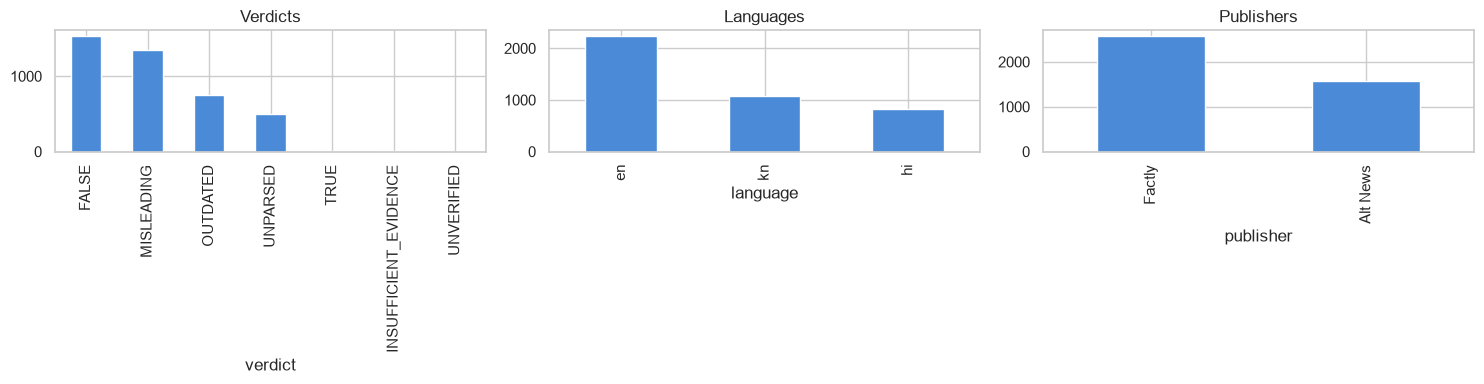

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df['verdict'].fillna('UNPARSED').value_counts().plot.bar(ax=axes[0], color='#4a8ad6', title='Verdicts')
df['language'].value_counts().plot.bar(ax=axes[1], color='#4a8ad6', title='Languages')
df['publisher'].value_counts().plot.bar(ax=axes[2], color='#4a8ad6', title='Publishers')
plt.tight_layout(); plt.show()

In [3]:
pd.crosstab(df['language'], df['verdict'].fillna('UNPARSED'), margins=True)

verdict,FALSE,INSUFFICIENT_EVIDENCE,MISLEADING,OUTDATED,TRUE,UNPARSED,UNVERIFIED,All
language,,,,,,,,
en,755,4,988,349,6,131,1,2234
hi,377,0,244,210,0,0,0,831
kn,398,0,118,190,0,366,0,1072
All,1530,4,1350,749,6,497,1,4137


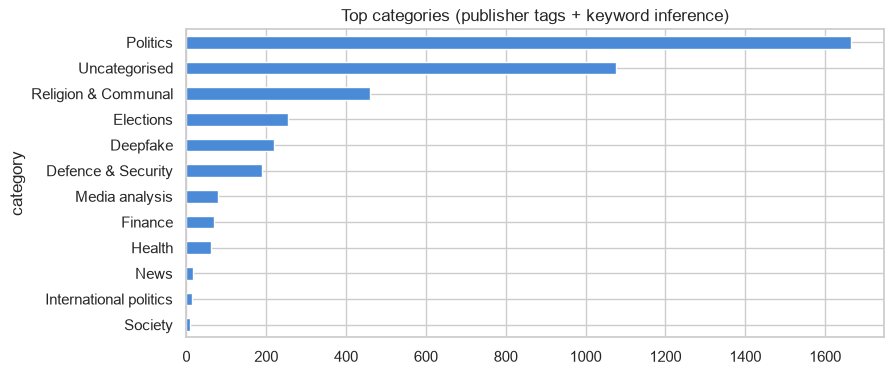

category_source
publisher_tag       1808
keyword_inferred    1252
none                1077
Name: count, dtype: int64

In [4]:
ax = df['category'].fillna('Uncategorised').value_counts().head(12).plot.barh(color='#4a8ad6'); ax.invert_yaxis(); ax.set_title('Top categories (publisher tags + keyword inference)'); plt.show()
df['category_source'].fillna('none').value_counts()

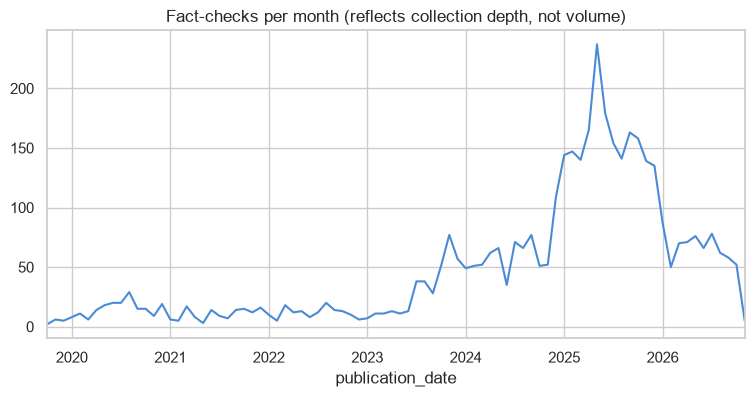

In [5]:
ts = pd.to_datetime(df['publication_date']).dt.to_period('M').value_counts().sort_index()
ax = ts.plot(color='#4a8ad6'); ax.set_title('Fact-checks per month (reflects collection depth, not volume)'); plt.show()

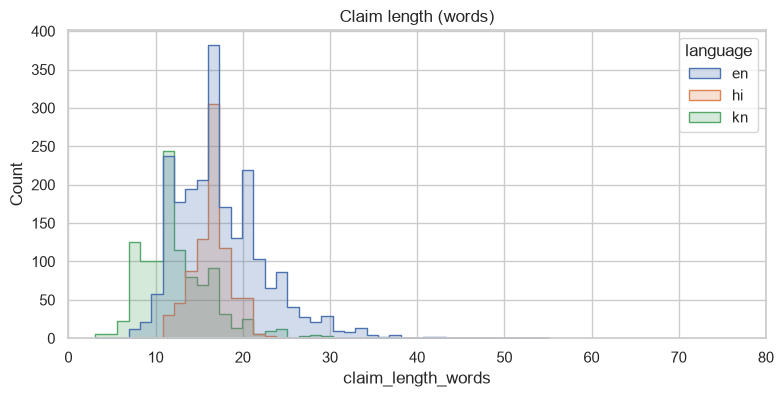

,count,mean,std,min,25%,50%,75%,max
language,,,,,,,,
en,2234.0,17.5,5.3,5.0,14.0,17.0,20.0,55.0
hi,831.0,16.3,2.2,9.0,15.0,16.0,18.0,26.0
kn,1072.0,12.5,4.3,3.0,10.0,12.0,15.0,53.0


In [6]:
ax = sns.histplot(data=df, x='claim_length_words', hue='language', bins=40, element='step'); ax.set_xlim(0, 80); ax.set_title('Claim length (words)'); plt.show()
df.groupby('language')['claim_length_words'].describe().round(1)

In [7]:
(df.isna().mean() * 100).round(1).sort_values(ascending=False).to_frame('missing %').head(10)

,missing %
category,26.0
category_source,26.0
verdict_raw,12.0
verdict_rule,12.0
verdict,12.0
claim_id,0.0
claim_text,0.0
claim_source,0.0
fact_check_url,0.0
fact_check_title,0.0


## Observations
* FALSE, MISLEADING and OUTDATED make up ~99.7% of parsed verdicts — TRUE is nearly absent (selection bias).
* Politics and religion/communal topics dominate, reflecting these publishers' priorities.
* Claims are short (median ~20 words): TF-IDF features have little text to work with.

**Conclusion.** A classifier trained here can only distinguish *types* of debunked claims; retrieval of matching fact-checks must carry the evidence.